In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080114
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    (f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}").encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] pyexp
[学号] 20244080114
[机器指纹] e49d5bb589bc0a69
[RUN_ID] 20244080114-e49d5bb589bc0a69


# 一、Wigner 半圆定律

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Jupyter内嵌显示图片
%matplotlib inline

1. 编写 wigner_density(x)，接收⼀个整数或浮点数，返回半圆密度在  处的值，返回值为浮点数。不需要检查输⼊类型；函数应同时适⽤于 Python 和 NumPy的整数、浮点数。计算平⽅根时使⽤ numpy.sqrt，不要使⽤ math.sqrt。

In [3]:
def wigner_density(x):
    """计算半圆密度函数在x处的值"""
    x = np.asarray(x, dtype=float)
    # 初始化结果为0
    result = np.zeros_like(x)
    # |x| <= 2 时计算密度
    mask = np.abs(x) <= 2
    result[mask] = (1 / (2 * np.pi)) * np.sqrt(4 - x[mask] ** 2)
    # 单个输入时返回浮点数
    return result.item() if result.ndim == 0 else result

2. 编写 generate_wigner(n)，接收正整数 ，返回⼀个随机⽣成的 Wigner 矩阵，可以使⽤ NumPy 的⼆维数组或矩阵表⽰。若输⼊不是整数或不是正数，应抛出合适的异常。

In [4]:
def generate_wigner(n):
    """生成n×n的Wigner对称随机矩阵"""
    # 输入合法性检查
    if not isinstance(n, (int, np.integer)):
        raise TypeError("n必须是整数")
    if n <= 0:
        raise ValueError("n必须是正整数")
    
    # 生成随机矩阵，取上三角后对称化
    random_mat = np.random.normal(loc=0, scale=np.sqrt(1/n), size=(n, n))
    upper_tri = np.triu(random_mat)  # 提取上三角（含对角线）
    wigner_mat = upper_tri + upper_tri.T - np.diag(np.diag(upper_tri))
    return wigner_mat

3. 编写 get_spectrum(matrix)，接收 NumPy 矩阵或⼆维 NumPy 数组，返回包含其全部特征值的 NumPy 数组，按⾮递减顺序排列。本函数不需要检查输⼊类型。

In [5]:
def get_spectrum(matrix):
    """返回矩阵特征值的非递减数组"""
    eigenvalues = np.linalg.eigvalsh(matrix)
    return eigenvalues

4. 画⼀张包含四个纵向排列⼦图的图。对 ⽤蓝⾊、标准化的直⽅图展⽰随机 nn =100,200,500,1000n×n，每个⼦图分别 Wigner 矩阵的特值，并叠加红⾊的半圆密度曲线。根据图形说明： ⼤约达到多少时，半圆密度能较好地拟合特征值分布？使⽤ Kolmogorov–Smirnov 检验作更严格⽐较是可选任务。特征值计算可能较慢，尤其是远⼤于 1000 阶的矩阵。

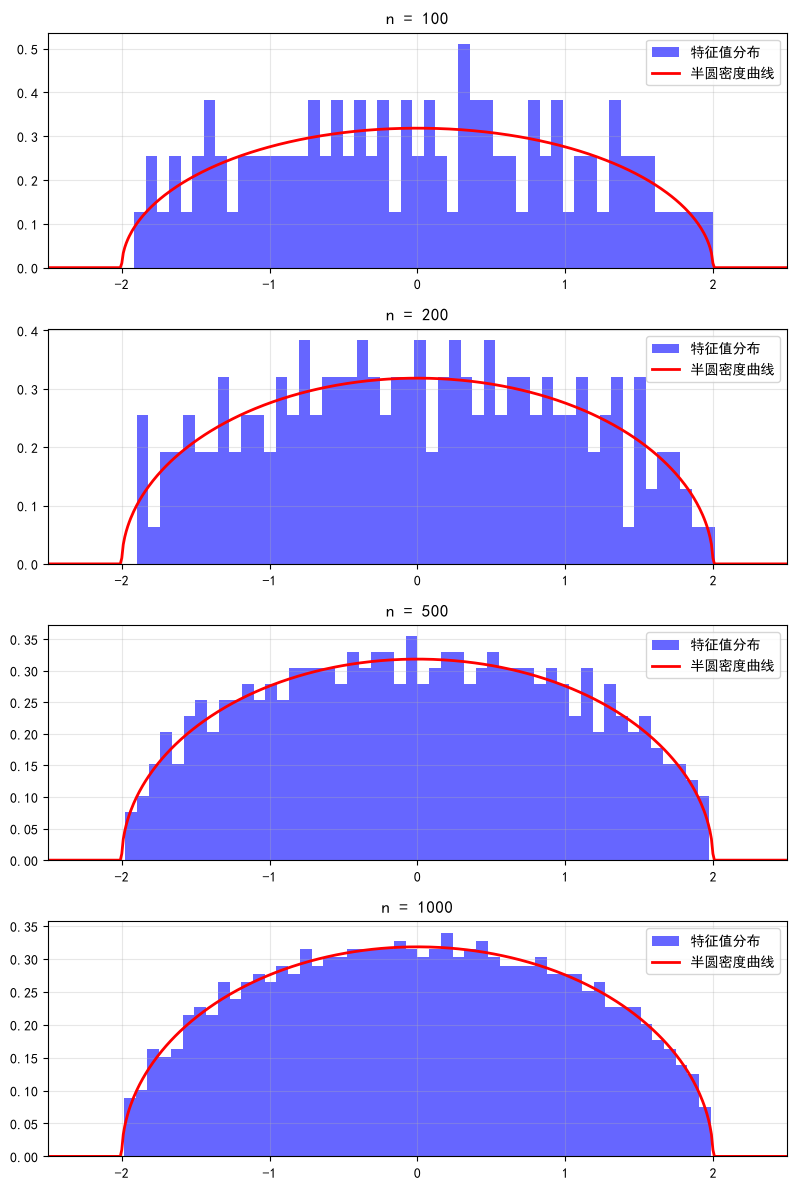

In [6]:
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 解决坐标轴负号显示异常

n_list = [100, 200, 500, 1000]
x_curve = np.linspace(-2.5, 2.5, 500)
y_curve = wigner_density(x_curve)

# 创建4行1列的子图
fig, axes = plt.subplots(4, 1, figsize=(8, 12), dpi=100)

for ax, n in zip(axes, n_list):
    # 生成矩阵并计算特征值
    wigner_mat = generate_wigner(n)
    eig_vals = get_spectrum(wigner_mat)
    
    # 绘制标准化直方图
    ax.hist(eig_vals, bins=50, density=True, color='blue', alpha=0.6, label='特征值分布')
    # 绘制理论密度曲线
    ax.plot(x_curve, y_curve, color='red', linewidth=2, label='半圆密度曲线')
    
    ax.set_title(f'n = {n}')
    ax.set_xlim(-2.5, 2.5)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 二、Conway 生命游戏

1. 编写 is_valid_board(board)，接收⼀个 NumPy ndarray，若它是有效的⽣命游戏棋盘（⼆维、元素仅为 0 或 1）则返回 Python 布尔值 True，否则返回False。

In [7]:
def is_valid_board(board):
    """检查是否为有效的生命游戏棋盘"""
    # 检查是否为numpy数组
    if not isinstance(board, np.ndarray):
        return False
    # 检查是否为二维
    if board.ndim != 2:
        return False
    # 检查元素是否仅为0或1
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

2. 编写 gol_step(board)，接收⼀个  m×n棋盘，返回同样⼤⼩的 NumPy 数组，表⽰下⼀步的棋盘。函数应先检查输⼊是否为有效棋盘，⽆效时抛出合适的异常。计算某个细胞的下⼀状态时，应使⽤原棋盘中的邻居状态。

In [8]:
def gol_step(board):
    """计算生命游戏下一步的棋盘状态"""
    # 输入检查
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    
    m, n = board.shape
    # 计算8个方向的邻居总数（环绕边界）
    neighbors = np.zeros_like(board)
    # 上下
    neighbors += np.roll(board, 1, axis=0)
    neighbors += np.roll(board, -1, axis=0)
    # 左右
    neighbors += np.roll(board, 1, axis=1)
    neighbors += np.roll(board, -1, axis=1)
    # 四个对角
    neighbors += np.roll(np.roll(board, 1, axis=0), 1, axis=1)
    neighbors += np.roll(np.roll(board, 1, axis=0), -1, axis=1)
    neighbors += np.roll(np.roll(board, -1, axis=0), 1, axis=1)
    neighbors += np.roll(np.roll(board, -1, axis=0), -1, axis=1)
    
    # 按规则更新状态
    new_board = np.zeros_like(board)
    # 活细胞：2或3个邻居则存活
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 死细胞：恰好3个邻居则复活
    new_board[(board == 0) & (neighbors == 3)] = 1
    
    return new_board

3. 编写 draw_gol_board(board)，将棋盘画成  m×n个⽅格：活细胞为⿊⾊，死细胞为⽩⾊。图中不显⽰⽹格线、轴标签或轴刻度。可以使⽤plt.xticks()、plt.yticks() 和 plt.get_cmap() 等函数。

In [9]:
def draw_gol_board(board):
    """绘制生命游戏棋盘"""
    plt.figure(figsize=(6, 6))
    # gray_r反转灰度：1对应黑色，0对应白色
    plt.imshow(board, cmap='gray_r', vmin=0, vmax=1)
    # 隐藏坐标轴、刻度
    plt.axis('off')
    plt.tight_layout()
    plt.show()

简单测试

棋盘有效吗？ True
初始棋盘：


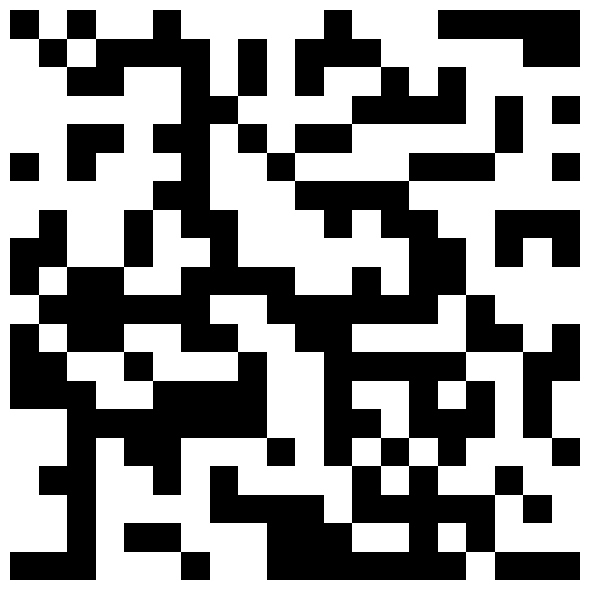

演化一步后：


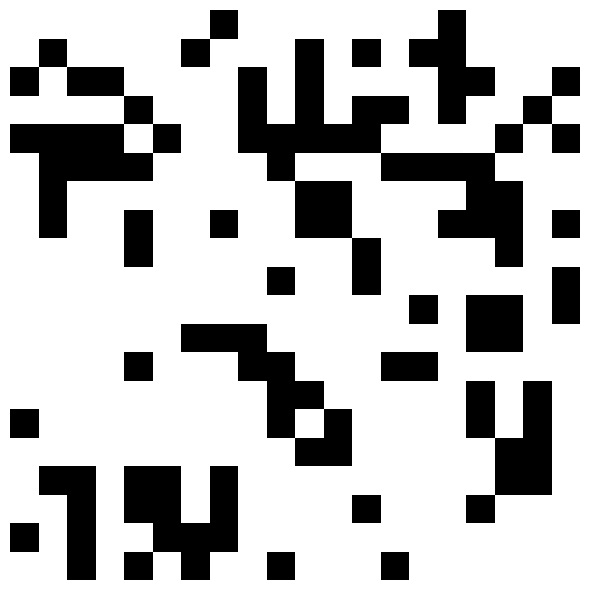

In [10]:
# 测试：生成一个随机棋盘，演化一步并绘制
test_board = np.random.randint(0, 2, size=(20, 20))
print("棋盘有效吗？", is_valid_board(test_board))
print("初始棋盘：")
draw_gol_board(test_board)

next_board = gol_step(test_board)
print("演化一步后：")
draw_gol_board(next_board)

# 三、Pandas 鸢尾花数据集处理

In [11]:
import pandas as pd

# 读取CSV文件
df = pd.read_csv('iris.csv')

print("      数据集基础信息")
print(f"数据点数量：{df.shape[0]} 行")
print("\n每列数据类型：")
print(df.dtypes)
print("\n列名列表：")
print(df.columns.tolist())
print(f"\n花卉种类数量：{df['Species'].nunique()} 种")
print(f"花卉种类名称：{df['Species'].unique().tolist()}")

      数据集基础信息
数据点数量：150 行

每列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

列名列表：
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

花卉种类数量：3 种
花卉种类名称：['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']


2. 已知数据的第 35 个和第 38 个数据⾏有误（不计列标题）。将第 35 ⾏改为4.9,3.1,1.5,0.2,"setosa"，其中原⽂件的第四项测量有误第 38 ⾏改为4.9,3.6,1.4,0.1,"setosa"，其中原⽂件的第⼆、三项测量有误。请在DataFrame 中完成修改，并检查修改后的两⾏。若采⽤从 0 开始的默认⾏索引，这两⾏的索引分别是 34 和 37。

In [12]:
# 修改第35行（索引34）：萼片长、萼片宽、花瓣长、花瓣宽、物种
df.iloc[34, 1:] = [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
# 修改第38行（索引37）
df.iloc[37, 1:] = [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

# 检查修改结果
print("修改后的两行数据：")
print(df.iloc[[34, 37]])

修改后的两行数据：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


3. 添加两列新特征：Petal.Ratio 为花瓣⻓度除以花瓣宽度；Sepal.Ratio 为萼⽚⻓度除以萼⽚宽度。

In [13]:
# 花瓣长宽比、萼片长宽比
df['Petal.Ratio'] = df['PetalLengthCm'] / df['PetalWidthCm']
df['Sepal.Ratio'] = df['SepalLengthCm'] / df['SepalWidthCm']

# 查看前5行确认新列
print("添加新列后前5行：")
print(df.head())

添加新列后前5行：
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Petal.Ratio  Sepal.Ratio  
0          7.0     1.457143  
1          7.0     1.633333  
2          6.5     1.468750  
3          7.5     1.483871  
4          7.0     1.388889  


4. 将更正并扩展后的 DataFrame 保存为 iris_corrected.csv，并随作业提交。

In [14]:
# 保存为新文件，不保留行索引
df.to_csv('iris_corrected.csv', index=False, encoding='utf-8')
print("文件已保存为 iris_corrected.csv")

文件已保存为 iris_corrected.csv


5. 按花卉种类分组，分别计算 Petal.Ratio 和 Sepal.Ratio 的平均值、中位数、最⼩值、最⼤值和标准差。使⽤合适的 groupby() 或聚合操作⼀次获得这些结果.

In [15]:
# 按花卉种类分组，一次性计算多个统计量
group_stats = df.groupby('Species')[['Petal.Ratio', 'Sepal.Ratio']].agg(
    ['mean', 'median', 'min', 'max', 'std']
)

print("                      分组统计结果 ")
print(group_stats.round(4))

                      分组统计结果 
                Petal.Ratio                               Sepal.Ratio          \
                       mean  median     min   max     std        mean  median   
Species                                                                         
Iris-setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
Iris-versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
Iris-virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                         
                    min     max     std  
Species                                  
Iris-setosa      1.2683  1.9565  0.1187  
Iris-versicolor  1.7647  2.8182  0.2287  
Iris-virginica   1.8235  2.9615  0.2470  
